# Sector clustering vs statistical (correlation) clustering
**ARPM script:** `s_shrink_corr_clusters` · **Labs:** Correlation clustering, Distance matrix for correlation clustering, Clustering in the stock market

**In plain words:** do stocks that *move together* line up with their official GICS sector?

1. prices → log-returns → correlation matrix $\hat{c}^2$
2. **sector clustering:** sort $\hat{c}^2$ by sector label and look for bright diagonal blocks
3. **statistical clustering:** turn each stock into a point (simulated from $N(0,\hat{c}^2)$), run k-means, sort by the clusters found
4. **distance** $d_{ij}=\sqrt{2(1-\hat{c}^2_{ij})}$ → minimum spanning tree = the market's skeleton

Changes from ARPM's original: data path via `clustering_lab.paths`, fixed seed. Code otherwise unchanged.

In [29]:
# --- PyCharm plumbing (not ARPM code) -------------------------------------
# Find the unit root from wherever the notebook runs, so `clustering_lab`
# imports and the data path work in PyCharm, Jupyter or a test run.
import sys
from pathlib import Path

UNIT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "clustering_lab").is_dir())
if str(UNIT_ROOT) not in sys.path:
    sys.path.insert(0, str(UNIT_ROOT))

from clustering_lab.paths import stocks_csv_path, OUTPUTS_DIR
STOCKS_CSV = stocks_csv_path()   # data/db_stocks_sp.csv (or $ARPM_DB_STOCKS_SP)
print("data:", STOCKS_CSV)

data: C:\Dev\Projects\ARPM\probabilistic_machine_learning\unit3_autoencoders_graphical_clustering\data\db_stocks_sp.csv


In [30]:
import pandas as pd
from numpy import isnan, where

from numpy import argsort, array, average, bincount, corrcoef, cumsum, \
                  diff, eye, ix_, log, max, min, r_, sqrt, zeros
from numpy.random import multivariate_normal
from networkx import draw_networkx, from_numpy_array, kamada_kawai_layout, minimum_spanning_tree
from sklearn.cluster import KMeans
from pandas import read_csv
from seaborn import heatmap, lineplot, scatterplot
from matplotlib.pyplot import show, xticks, yticks
from numpy.random import seed
seed(42)  # added: reproducible k-means / MST colouring

## Load data
Stock values with a 2-row header (sector, ticker) from `db_stocks_sp`.

In [32]:
# loading db_stocks_sp.csv
# csv has 2 header rows - (sector on top, then ticker underneath)
# index_col = 0 (the first column 'dates' become the row labels
db_stocks_sp = read_csv(STOCKS_CSV, index_col=0, header=[0, 1])
# stocks values
v = array(db_stocks_sp)

# get the number of columns/stocks
n_bar = v.shape[1]
# get the list of distinct sectors names
sectors = array(db_stocks_sp.columns.levels[0])
# sectors indices - getting the integer value for each stock
labels = array(db_stocks_sp.columns.codes)[0, :]

db_stocks_sp.head()

sector     HealthCare Materials InformationTechnology HealthCare           \
date                A        AA                  AAPL        ABC      ABT   
2006-07-31    26.5965   26.5955                67.362    19.5346  39.4580   
2006-08-01    26.2318   26.0094                66.648    19.5392  39.2432   
2006-08-02    26.3066   26.4646                67.491    19.6255  38.9459   
2006-08-03    26.3721   26.4200                69.047    19.6845  39.0037   
2006-08-04    26.2318   26.3932                67.778    19.4074  39.0202   

sector     Financials InformationTechnology ConsumerStaples  \
date              ACE                  ADBE             ADM   
2006-07-31    44.8774                 28.51         38.9938   
2006-08-01    44.5900                 28.34         38.9051   
2006-08-02    44.4593                 32.24         37.9835   
2006-08-03    44.3722                 32.53         37.2213   
2006-08-04    44.1458                 31.72         36.2553   

sector     InformationTechnology Utilities  ... Materials Utilities  \
date                        ADSK       AEE  ...         X       XEL   
2006-07-31                 34.11   36.3607  ...   59.4014   15.2350   
2006-08-01                 32.98   36.7278  ...   58.2053   15.3566   
2006-08-02                 32.75   36.6148  ...   58.1205   15.5467   
2006-08-03                 33.74   36.0077  ...   56.9621   15.4402   
2006-08-04                 33.31   36.0359  ...   55.7094   15.5162   

sector     Financials InformationTechnology   Energy HealthCare  \
date               XL                  XLNX      XOM       XRAY   
2006-07-31    51.8924               17.4410  58.7139    30.2250   
2006-08-01    50.9882               17.2003  59.0953    30.0898   
2006-08-02    50.5646               17.2347  59.3553    30.3119   
2006-08-03    50.1410               17.4410  59.2600    30.4181   
2006-08-04    50.1491               17.2519  59.5373    30.6016   

sector     InformationTechnology        ConsumerDiscretionary Financials  
date                         XRX   YHOO                   YUM       ZION  
2006-07-31               12.8205  27.14               19.8962    75.5086  
2006-08-01               12.9478  26.94               19.9492    75.2328  
2006-08-02               13.1662  26.56               20.3074    75.3523  
2006-08-03               13.0843  26.92               20.7185    76.1245  
2006-08-04               13.1116  26.99               20.7804    76.3083  

[5 rows x 392 columns]

<h1 style="font-weight: bold; font-size:14px; line-height:1.5em;">1. Compute 
<a style="color:#3c9591" href="https://www.arpm.co/lab/redirect.php?permalink=SampCorrDeffEstim" class="@formulas #SampCorrDeffEstim"> the correlation</a>
of <a style="color:#3c9591" href="https://www.arpm.co/lab/redirect.php?permalink=aosfiaod-copy-3" class="@formulas #aosfiaod-copy-3">log-returns</a> and sort it by sectors</h1>

In [33]:
# the daily log-returns (lnVt - lnVt-1)
# axis = 0 -> means get the difference 'down the rows' day to day for each stock
# finds the difference between 2 values
eps = diff(log(v), axis=0)
# getting the historical correlation of every pair of stocks
# .T(transpose) is needed because corrcoef treats rows as the variables and our stocks are columns.
# returns an n_bar x n_bar table showing how strongly stocks move together, diagonals are all 1's
c2_hist = corrcoef(eps.T)

# sorting/grouping index for sectors together (Energy, Financials...)
i_s = argsort(labels)
# correlation matrix sorted/shuffled by the same grouping of sectors above (using 'ix_')
c2_sec = c2_hist[ix_(i_s, i_s)]

In [34]:
# ---- data check (my addition, not ARPM) ----
print("prices:", v.shape, " (days × stocks)")
print("returns:", eps.shape, " correlation:", c2_hist.shape)
print("NaNs in prices:", int(isnan(v).sum()), " NaNs in correlation:", int(isnan(c2_hist).sum()))
print("dates:", db_stocks_sp.index[0], "→", db_stocks_sp.index[-1])
print("\nstocks per sector:")
print(pd.Series(labels).value_counts().sort_index().set_axis(sectors).to_string())

same = labels[:, None] == labels[None, :]
off = ~eye(n_bar, dtype=bool)
print(f"\navg correlation, same sector:      {c2_hist[same & off].mean():.3f}")
print(f"avg correlation, different sector: {c2_hist[~same].mean():.3f}")

prices: (1600, 392)  (days × stocks)
returns: (1599, 392)  correlation: (392, 392)
NaNs in prices: 0  NaNs in correlation: 0
dates: 2006-07-31 → 2012-12-05

stocks per sector:
ConsumerDiscretionary        61
ConsumerStaples              35
Energy                       32
Financials                   65
HealthCare                   40
Industrials                  53
InformationTechnology        48
Materials                    26
TelecommunicationServices     4
Utilities                    28

avg correlation, same sector:      0.553
avg correlation, different sector: 0.454


<h1 style="font-weight: bold; font-size:14px; line-height:1.5em;">2. Compute initial clustering by computing average of each sector</h1>

In [35]:
# simulate a multivariate normal distribution of 784(2x392) fake days of returns
# with mean = 0, and the same correlation as c2_hist
# returns 784 rows (fake days) X 392 columns (stocks)
# now each stock is a column, a list of 784 numbers, i.e a point in 784 dimensional space
# simulating because real returns have different volatilities, simulating from correlation matrix
# puts each stock on a volatility of 1, only co-movement remains
# simulating this way because only correlation really matters.
x = multivariate_normal(zeros(n_bar), c2_hist, 2*n_bar)
# number of sectors
k_bar = sectors.shape[0]

# we need more fake days that stocks otherwise the simulated cloud cant reproduce a 392x392 corr matrix.
# compute initial clustering 
c0 = zeros((2*n_bar, k_bar))
# for each sector k
# pick that sector's stocks (labels == k)
# average across the stocks for each fake day (average(..., axis=1)) for each sector
# returns 10 starting centroids, 1 per sector (c0:784x10)
# starting at the center for comparability and stability.
for k in range(k_bar):
    c0[:, k] = average(x[:, labels == k], axis=1)

In [36]:
# ---- Cell 2 check (my addition, not ARPM) ----
from numpy import unravel_index, argmax, argmin

j_sim = x.shape[0]
tickers = array([t for s, t in db_stocks_sp.columns])
print("x (scenarios × stocks):", x.shape, "  c0 (scenarios × sectors):", c0.shape)

# 1) does the simulated cloud reproduce the historical correlation?
c2_sim = corrcoef(x.T)
print(f"avg |simulated corr − historical corr|: {abs(c2_sim - c2_hist).mean():.3f}")

# 2) most- and least-correlated pairs: is the point-distance = correlation-distance?
i_hi, j_hi = unravel_index(argmax(c2_hist - 2*eye(n_bar)), c2_hist.shape)
i_lo, j_lo = unravel_index(argmin(c2_hist), c2_hist.shape)
print(f"\n{'pair':<16}{'corr':>7}{'sqrt(2(1-corr))':>17}{'|x_i - x_j|/sqrt(J)':>21}")
for i, j in [(i_hi, j_hi), (i_lo, j_lo)]:
    gap = sqrt(sum((x[:, i] - x[:, j])**2) / j_sim)
    print(f"{tickers[i]+' vs '+tickers[j]:<16}{c2_hist[i, j]:>7.3f}"
          f"{sqrt(2*(1 - c2_hist[i, j])):>17.3f}{gap:>21.3f}")

x (scenarios × stocks): (784, 392)   c0 (scenarios × sectors): (784, 10)
avg |simulated corr − historical corr|: 0.023

pair               corr  sqrt(2(1-corr))  |x_i - x_j|/sqrt(J)
VNO vs BXP        0.923            0.392                0.384
FDO vs NEM        0.039            1.387                1.358


<h1 style="font-weight: bold; font-size:14px; line-height:1.5em;">3. Determine clusters and sort correlation matrix accordingly</h1>

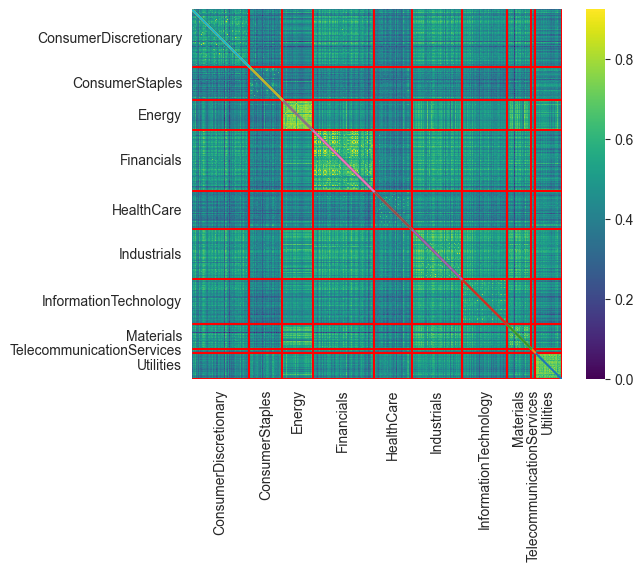

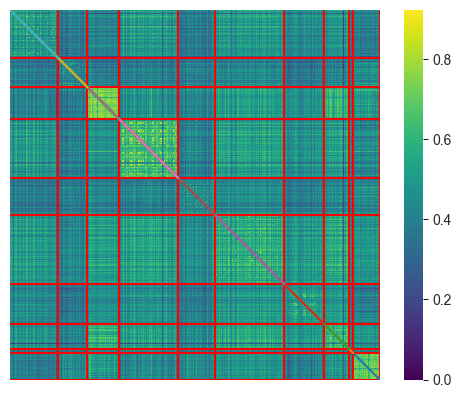

In [21]:
# Run  k-means and draw the 2 heatmaps
# clustering stocks
# so transpose x to 392 stocks x 784 columns (x.T)
# scikit-learn fit() wants rows = the things being clustered
# start at the 10 sector-avg stcoks from cell 2, transposed to 10 rows x 784 columns to match (init=c0.T)
# run once (n_init=1)
kmeans = KMeans(n_clusters=k_bar, init=c0.T, n_init=1).fit(x.T)

# kmeans is our fitted model
# sorting index for clusters (1 cluster number per stock (kmeans.labels_))
i_c = argsort(kmeans.labels_)
# correlation matrix sorted/grouping by clusters instead of sector
c2_clus = c2_hist[ix_(i_c, i_c)]

############################################# plots #############################################
# sector clusters
# counts stocks per cluster (bincount)
# gives running totals (cumsum)
l_s = cumsum(bincount(labels[i_s]))
# zeros the diagonal (eye(n_bar))
# vmin / vmax gives both plots an identical colour scale
heatmap(c2_sec - eye(n_bar), vmin=min(c2_hist - eye(n_bar)), 
        vmax=max(c2_hist - eye(n_bar)), cmap = 'viridis', square=True)
[lineplot(x=[1, n_bar], y=[l_s[k], l_s[k]], c='r') for k in reversed(range(10))]
[lineplot(x=[l_s[k], l_s[k]], y=[1, n_bar], estimator=None, c='r') for k in reversed(range(10))]
[lineplot(x=[1, l_s[k]], y=[1, l_s[k]]) for k in reversed(range(10))]
xticks(r_[l_s[0]/2, l_s[:-1] + diff(l_s)/2], sectors, rotation=90)
yticks(r_[l_s[0]/2, l_s[:-1] + diff(l_s)/2], sectors)
show()

# correlation clusters - same approach as above plot
l_c = cumsum(bincount(kmeans.labels_[i_c]))
heatmap(c2_clus - eye(n_bar), vmin=min(c2_hist - eye(n_bar)), 
        vmax=max(c2_hist - eye(n_bar)), cmap = 'viridis', square=True)
[lineplot(x=[1, n_bar], y=[l_c[k], l_c[k]], c='r') for k in reversed(range(10))]
[lineplot(x=[l_c[k], l_c[k]], y=[1, n_bar], estimator=None, c='r') for k in reversed(range(10))]
[lineplot(x=[1, l_c[k]], y=[1, l_c[k]]) for k in reversed(range(10))]
xticks([]); yticks([])
show()

In [24]:
# ---- Cell 3 check (my addition, not ARPM) ----
import pandas as pd

cl = kmeans.labels_
tickers = array([t for s, t in db_stocks_sp.columns])

# 1) how many stocks did k-means move out of their sector's cluster?
print("sector sizes: ", bincount(labels, minlength=k_bar))
print("cluster sizes:", bincount(cl, minlength=k_bar))
print(f"stocks still in their own sector's cluster: {(cl == labels).mean():.1%}\n")

# 2) where did the movers go? (cluster k started at sector k's centre, so it carries that name)
moves = pd.Series([f"{sectors[a]} → {sectors[b]}-cluster" for a, b in zip(labels, cl) if a != b])
print("biggest moves:\n", moves.value_counts().head(10).to_string(), "\n")

# 3) which grouping has tighter groups?
def avg_corr(lbl):
    same = lbl[:, None] == lbl[None, :]
    off = ~eye(n_bar, dtype=bool)
    return c2_hist[same & off].mean(), c2_hist[~same].mean()

for name, lbl in [("sectors", labels), ("k-means clusters", cl)]:
    w, b = avg_corr(lbl)
    print(f"{name:<18} avg corr inside groups {w:.3f} | between groups {b:.3f} | gap {w - b:.3f}")

# 4) where did our two pairs end up?
for t in ["VNO", "BXP", "FDO", "NEM"]:
    i = where(tickers == t)[0][0]
    print(f"{t}: sector {sectors[labels[i]]:<22} → {sectors[cl[i]]}-cluster")

sector sizes:  [61 35 32 65 40 53 48 26  4 28]
cluster sizes: [51 31 34 62 39 74 42 27  4 28]
stocks still in their own sector's cluster: 87.2%

biggest moves:
 ConsumerDiscretionary → Industrials-cluster              14
InformationTechnology → Industrials-cluster               8
Industrials → Materials-cluster                           5
Materials → Industrials-cluster                           3
Financials → Industrials-cluster                          3
ConsumerStaples → ConsumerDiscretionary-cluster           3
ConsumerDiscretionary → InformationTechnology-cluster     2
Industrials → ConsumerDiscretionary-cluster               2
Materials → ConsumerDiscretionary-cluster                 2
HealthCare → Industrials-cluster                          1 

sectors            avg corr inside groups 0.553 | between groups 0.454 | gap 0.098
k-means clusters   avg corr inside groups 0.563 | between groups 0.453 | gap 0.110
VNO: sector Financials             → Financials-cluster
BXP: sector Fin

<h1 style="font-weight: bold; font-size:14px; line-height:1.5em;">4. Compute 
<a style="color:#3c9591" href="https://www.arpm.co/lab/redirect.php?permalink=Eucl_dist" class="@formulas #Eucl_dist">distance matrix</a> and <a style="color:#3c9591" href="https://en.wikipedia.org/wiki/Minimum_spanning_tree">minimum spanning tree</a> 
</h1>

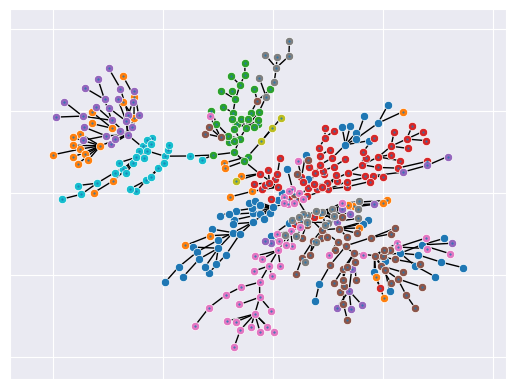

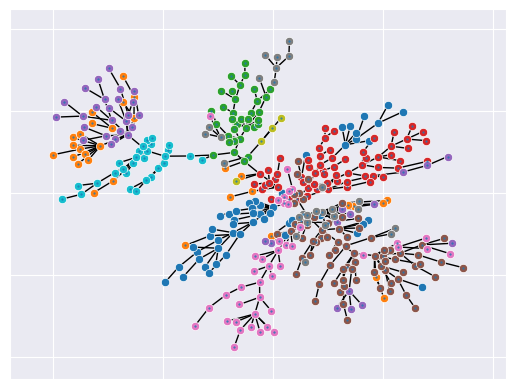

In [26]:
# Distance matrix and minimum spanning tree

# distance matrix
# the correlation distance already verified in Cell 2
d = sqrt(2*(1 - c2_hist))

# minimum_spanning_tree(), keeps only the 391 links
# build a network where ever stock is a dot (from_numpy_array(d)) and every pair is linked
# each stock gets linked to its most similar neighbour(s)
# the result is a skeleton of the market.
mst = minimum_spanning_tree(from_numpy_array(d))

##################################### plots #####################################
# colors by sectors
pos = kamada_kawai_layout(mst)
draw_networkx(mst, pos=pos, node_shape='.', node_size=1, with_labels=False)
idx = [i_s[int(l_s[k - 1] if k > 0 else 0):int(l_s[k])] for k in range(k_bar)]
[scatterplot(x=[pos[id][0] for id in idx[k]] , y=[pos[id][1] for id in idx[k]])\
 for k in range(k_bar)]; show();

# colors by clusters
pos = kamada_kawai_layout(mst)
draw_networkx(mst, pos=pos, node_shape='.', node_size=1, with_labels=False)
idx = [i_c[int(l_c[k - 1] if k > 0 else 0):int(l_c[k])] for k in range(k_bar)]
[scatterplot(x=[pos[id][0] for id in idx[k]] , y=[pos[id][1] for id in idx[k]])\
 for k in range(k_bar)]; show();

In [27]:
# ---- Cell 4 check (my addition, not ARPM) ----
tickers = array([t for s, t in db_stocks_sp.columns])
print("nodes:", mst.number_of_nodes(), " edges:", mst.number_of_edges(),
      f" (a full graph would have {n_bar*(n_bar-1)//2:,})")

# 1) does the tree rediscover sectors without being told them?
same = [labels[a] == labels[b] for a, b in mst.edges()]
share = bincount(labels) / n_bar
print(f"MST links joining same-sector stocks: {sum(same)}/{len(same)} = {sum(same)/len(same):.1%}"
      f"  (random pairs would give {(share**2).sum():.1%})")

# 2) hubs (central, market-like) and leaves (loners)
deg = pd.Series(dict(mst.degree())).sort_values(ascending=False)
hubs = pd.DataFrame({"ticker": tickers[deg.index], "sector": sectors[labels[deg.index]],
                     "links": deg.values})
print("\nbiggest hubs:\n", hubs.head(8).to_string(index=False))
print(f"\nleaves (only 1 link): {(deg == 1).sum()} of {n_bar} stocks")

# 3) our four stocks: who are their nearest neighbours in the skeleton?
for t in ["VNO", "BXP", "FDO", "NEM"]:
    i = where(tickers == t)[0][0]
    nb = [tickers[j] for j in mst.neighbors(i)]
    print(f"{t:<4} links={mst.degree(i)}  neighbours: {', '.join(nb)}")

nodes: 392  edges: 391  (a full graph would have 76,636)
MST links joining same-sector stocks: 310/391 = 79.3%  (random pairs would give 12.0%)

biggest hubs:
 ticker                sector  links
   BEN            Financials     17
    DD             Materials     16
   UTX           Industrials     13
   JNJ            HealthCare     13
  TROW            Financials     10
   DTE             Utilities     10
    HD ConsumerDiscretionary     10
   APA                Energy     10

leaves (only 1 link): 237 of 392 stocks
VNO  links=6  neighbours: BXP, SPG, KIM, PLD, TROW, GE
BXP  links=3  neighbours: VNO, AVB, HST
FDO  links=2  neighbours: DLTR, TGT
NEM  links=1  neighbours: FCX


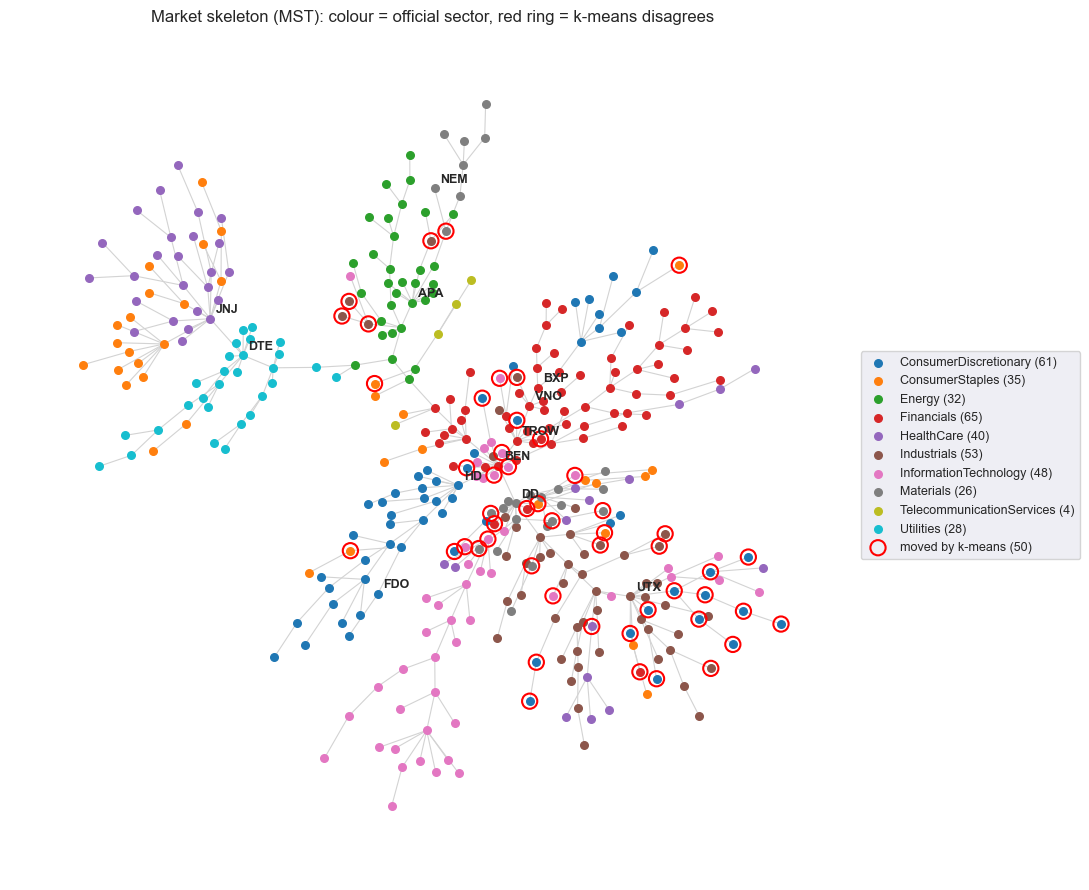

In [28]:
# ---- one readable MST plot (my addition, not ARPM) ----
import matplotlib.pyplot as plt
from networkx import draw_networkx_edges

cl = kmeans.labels_
moved = cl != labels
colours = plt.get_cmap("tab10")
xy = array([pos[i] for i in range(n_bar)])

fig, ax = plt.subplots(figsize=(11, 9))
draw_networkx_edges(mst, pos=pos, ax=ax, edge_color="lightgrey", width=0.8)
for k in range(k_bar):
    m = labels == k
    ax.scatter(xy[m, 0], xy[m, 1], s=30, color=colours(k % 10),
               label=f"{sectors[k]} ({m.sum()})", zorder=2)
ax.scatter(xy[moved, 0], xy[moved, 1], s=120, facecolors="none", edgecolors="red", lw=1.5,
           label=f"moved by k-means ({moved.sum()})", zorder=3)

# label the 8 biggest hubs plus our four stocks
deg = dict(mst.degree())
to_label = set(sorted(deg, key=deg.get, reverse=True)[:8])
to_label |= {i for i, t in enumerate(tickers) if t in ["VNO", "BXP", "FDO", "NEM"]}
for i in to_label:
    ax.annotate(tickers[i], xy[i], xytext=(4, 4), textcoords="offset points",
                fontsize=9, weight="bold")

ax.set_title("Market skeleton (MST): colour = official sector, red ring = k-means disagrees")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9); ax.axis("off")
plt.tight_layout(); show()

Conclusion:
On 392 S&P500 stcoks over 2006-2012, the official sectors capture most of the real correlation structure.

- Market Skeleton (MST) rediscovers 79% of the time without labels.
- k-means keeps 87% of stocks in place

The data-driven methods add 3 things the labels miss:
- a cyclicals group that cuts across sectors
- a REIT sub-group hidden inside Financials
- loners like gold miners that k-means forces into a group but the tree leaves out on its own.

Each method has a blind spot, k-means needs k fixed in advance and must assign very stock,
the tree shows structure but doesnt split it into groups.  And all of it is in-sample on a crisis period.
so the real test is whether it holds up on later data